# CPE 486/586 – Homework 3: Optimization and Linear Regression
**Name:** Shayan Rajput  
**UAH Charger ID / email:** sr1286@uah.edu

**PyPI package keyword:**  ***redkeymon*** https://pypi.org/project/redkeymon/  

**GitHub repo URL:** https://github.com/redkeymongh/redkeymon/tree/main/src/redkeymon/model  

**Commit hash:** 8e122fb



---
# Theory

## 1. Automatic differentiation and expression graph
$f(w,x,y,z)=wx+y^2z$

Graph: $a=w\cdot x,\; b=y^2,\; c=b\cdot z,\; f=a+c$

```
w ─┐
   (×)→ a ─┐
x ─┘        (+)→ f
y →(²)→ b ─┐ │
           (×)→ c ─┘
z ─────────┘
```

Forward pass ($w=1,x=2,y=3,z=4$): $a=2,\; b=9,\; c=36,\; f=38$.

Backward pass: $\partial f/\partial a=1$, $\partial a/\partial w=x=2$ so
$$\frac{\partial f}{\partial w}=1\cdot 2=\mathbf{2}.$$
(The $y^2z$ branch does not depend on $w$.)

## 2. Unconstrained optimization
**2.1** $f(x)=x^2-4x+4$: $f'(x)=2x-4=0\Rightarrow x=2$, $f''=2>0$ → minimum. **$f_{min}=f(2)=0$.**

**2.2** $f(x)=x^3-3x^2$: $f'(x)=3x^2-6x=3x(x-2)=0\Rightarrow x=0,\,2$. $f''(x)=6x-6$.
- $x=0$: $f''=-6<0$ → **local maximum**, value $f(0)=0$.
- $x=2$: $f''=6>0$ → **local minimum**, value $f(2)=8-12=-4$.

**2.3** $f(x,y)=x^2-y^2$: $\nabla f=(2x,\,-2y)=0\Rightarrow(0,0)$. Hessian $=\mathrm{diag}(2,-2)$ is indefinite → **saddle point**.

## 3. Lagrange multipliers
Minimize $f=x^2+y^2+z^2$ s.t. $x+2y+z=6$.

1. Lagrangian: $\mathcal L=x^2+y^2+z^2-\lambda(x+2y+z-6)$
2. System: $2x=\lambda,\; 2y=2\lambda,\; 2z=\lambda,\; x+2y+z=6$
3. Solve: $x=\lambda/2,\,y=\lambda,\,z=\lambda/2$; constraint gives $3\lambda=6\Rightarrow\lambda=2$. Critical point $(1,2,1)$, $f=6$.
4. Classification: Hessian of $f$ is $2I\succ0$ (convex) → **global minimum**; no maximum exists (f unbounded on the plane).
5. Role of the constraint: restricts the search to the plane $x+2y+z=6$. The minimum is the squared distance from the origin to the plane, $6^2/(1+4+1)=6$. $\lambda$ measures the sensitivity of the optimum to the constraint value.

## 4. Gradient descent on $J(w_1)=(w_1-5)^4+(w_1-3)^2+4$
**Iterations with $\eta=0.1$:**

| Iter | $w$ before | $J'(w)$ | $w$ after |
|---|---|---|---|
| 1 | 2 | $4(-3)^3+2(-1)=-110$ | $2+11=13$ |
| 2 | 13 | $4(8)^3+2(10)=2068$ | $13-206.8=-193.8$ |
| 3 | −193.8 | $\approx-3.14\times10^7$ | $\approx3.14\times10^6$ |
| 4 | $3.14\times10^6$ | $\approx1.24\times10^{20}$ | $\approx-1.2\times10^{19}$ |
| 5 | $-1.2\times10^{19}$ | $\approx-7.7\times10^{57}$ | $\approx7.7\times10^{56}$ |

The iterates **diverge** because $\eta=0.1$ is too large (at the start $J''=12(w-5)^2+2\approx110$, so stability needs $\eta\lesssim2/110\approx0.018$).

**Analytic (partial-derivative) method:** $J'=0$ with $u=w-5$ gives $2u^3+u+2=0\Rightarrow u\approx-0.835$, so $w^*\approx4.165$, $J(w^*)\approx5.84$. A smaller step (e.g. $\eta=0.01$) would converge toward this value, whereas $\eta=0.1$ does not.

## 5. Ridge (L2-regularized) regression
Loss: $L(w)=(y-Xw)^\top(y-Xw)+\lambda w^\top w$.

$\nabla_w L=-2X^\top(y-Xw)+2\lambda w=0\;\Rightarrow\;(X^\top X+\lambda I)\,w=X^\top y$

$$\hat w=(X^\top X+\lambda I)^{-1}X^\top y$$

**Impact:** for $\lambda>0$, $X^\top X+\lambda I$ is always invertible (handles collinearity); weights are shrunk toward 0 (adds bias, reduces variance, helps against overfitting). $\lambda\to0$ gives ordinary least squares; $\lambda\to\infty$ gives $w\to0$. The intercept is usually not penalized.

## 6. Assumptions of simple linear regression
1. Linearity: $y=\beta_0+\beta_1x+\varepsilon$ is linear in the parameters.
2. Errors have zero mean, $E[\varepsilon]=0$.
3. Independence of errors (no autocorrelation).
4. Homoscedasticity: constant error variance.
5. Normality of errors (needed for exact inference: CIs, t-tests).
6. $x$ is measured without error and is not constant (has variation).
7. No highly influential outliers.
(For multiple regression: no perfect multicollinearity.)

---
# Practice
## 7. Derivative with PyTorch autograd
τ = 2r·√(r/rₛ)·√(1−rₛ/r)

In [10]:
!pip install redkeymon

In [11]:
import torch
rs = 0.00887
r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)
tau = 2 * r * torch.sqrt(r / rs) * torch.sqrt(1 - rs / r)
tau.backward()
print("tau      =", tau.item())
print("dtau/dr  =", r.grad.item())   # expected ~5517.226

# analytic check: d/dr [2r sqrt((r-rs)/rs)] = 2 sqrt((r-rs)/rs) + r/sqrt(rs (r-rs))
import math
print("analytic =", 2*math.sqrt((30000.1-rs)/rs) + 30000.1/math.sqrt(rs*(30000.1-rs)))

tau      = 110344877.04827532
dtau/dr  = 5517.226005413796
analytic = 5517.226005413797


## 8. Linear regression with scikit-learn (steer angle → yaw rate)

In [12]:
import pandas as pd
from sklearn.linear_model import LinearRegression as SkLR
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

url = ("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/"
       "2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv")
df = pd.read_csv(url)
X, y = df[["steer_angle"]], df["yaw_rate"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
m = SkLR().fit(Xtr, ytr)
print("Intercept:", m.intercept_)
print("Slope    :", m.coef_[0])
print("Test R^2 :", r2_score(yte, m.predict(Xte)))
# Expected (random_state=42): intercept ~ -0.2072, slope ~ 0.0662, R^2 ~ 0.656

Intercept: -0.20719705434128108
Slope    : 0.06620846316922513
Test R^2 : 0.6555643761968142


## 9. Linear regression with PyTorch (Hydropower: BCR → AnnualProduction)


In [13]:
!pip install redkeymon

In [14]:
from redkeymon.model import LinearRegression
print(LinearRegression)

<class 'redkeymon.model.regression.LinearRegression'>


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split

hp = pd.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv")
x, y = hp["BCR"].values, hp["AnnualProduction"].values
xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.25, random_state=42)

Test R^2: 0.4620
w0 = -3035.748291015625  w1 = 11465.08984375


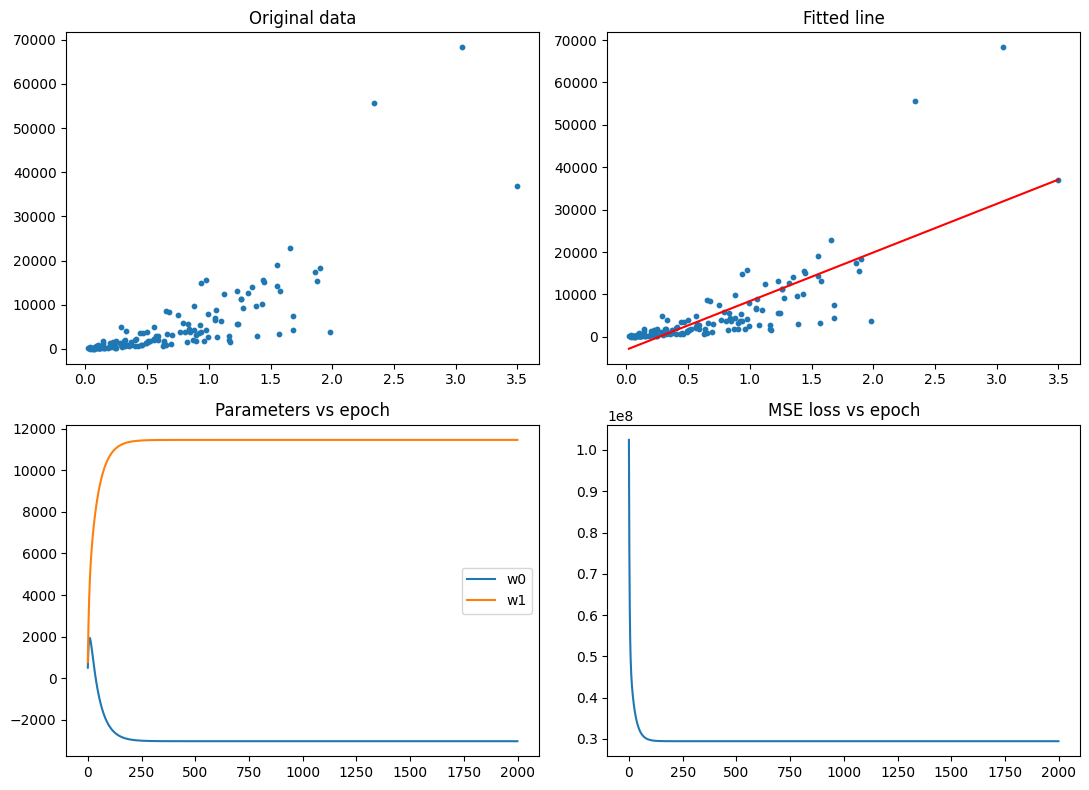

Predicted AnnualProduction for BCR=1.5: [14161.887]


In [16]:
model = LinearRegression(learning_rate=0.05, epochs=2000)
model.fit(xtr, ytr, xte, yte)
print("w0 =", model.w0.item(), " w1 =", model.w1.item())
model.analysis_plot()
print("Predicted AnnualProduction for BCR=1.5:", model.predict([1.5]))

---
## Reflection Report

UAH Email: sr1826@uah.edu

How I Used the AI Tool: I used Gemini and Claude for this assignment to figure out topics I didn’t know about and to troubleshoot any issues I ran into. I asked the AI agents to get a better understanding and make sure my work is being done in the correct manner to get all the points for the assignment.

Query: Link to chats provided below

How It Helped My Understanding: Using the AI models helped me understand the assignment more since I could ask the agents to troubleshoot any issues that came up for me. Some of the stuff we worked on I didn’t understand so having an agent help me out was beneficial for me to complete the assignment.


How would I approach this without the AI tools: Without the tools I would most likely use Stackoverflow for programming or reference documentation for GitHub and UV to help install the necessary packages I needed for this project. For more technical questions I would have asked the professor on how to perform some actions. I was able to do most of the work myself since I had some programming experince and I have taken Linear Algebra.


Links:

https://share.gemini.google/DR5ssoQMqcdT

https://claude.ai/share/6f9c6232-9cad-4cd3-bfe9-71ac0be925a1